In [2]:
# ! uv pip install scikit-learn
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline


In [3]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nyc_311_regression.csv"
)

df = pd.read_csv(DATA_PATH, parse_dates=["created_date"])

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (4668, 38)


In [5]:
df.head()

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,descriptor_2,location_type,incident_zip,...,y_coordinate_state_plane,open_data_channel_type,park_facility_name,park_borough,latitude,longitude,location,is_closed,resolution_hours,completion_hours
0,71179718,2026-11-19 01:42:26,2026-11-19 02:04:36,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,NaN,RESIDENTIAL BUILDING/HOUSE,10039.0,...,242527.0,PHONE,Unspecified,MANHATTAN,40.832338,-73.935432,POINT (-73.935431738007 40.832337915244),1,0.369444,0.369444
1,71171016,2026-11-19 01:34:18,2026-11-19 01:47:10,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,LOUD TALKING,NaN,RESIDENTIAL BUILDING/HOUSE,10009.0,...,206421.0,ONLINE,Unspecified,MANHATTAN,40.733252,-73.976030,POINT (-73.976030383539 40.733252130601),1,0.214444,0.214444
2,71171039,2026-11-19 01:33:55,2026-11-19 01:41:02,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - STREET/SIDEWALK,LOUD TALKING,NaN,STREET/SIDEWALK,10024.0,...,226231.0,MOBILE,Unspecified,MANHATTAN,40.787626,-73.978936,POINT (-73.978935878994 40.787626067455),1,0.118611,0.118611
3,71177582,2026-11-19 01:28:48,2026-11-19 01:54:06,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - COMMERCIAL,BANGING/POUNDING,NaN,CLUB/BAR/RESTAURANT,11211.0,...,199246.0,ONLINE,Unspecified,BROOKLYN,40.713555,-73.961886,POINT (-73.961886477712 40.713554678518),1,0.421667,0.421667
4,71174389,2026-11-19 01:27:53,2026-11-19 01:29:46,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,NaN,RESIDENTIAL BUILDING/HOUSE,11214.0,...,160824.0,PHONE,Unspecified,BROOKLYN,40.608101,-73.999384,POINT (-73.999384145633 40.608101083647),1,0.031389,0.031389


### Feature engineering

In [6]:
candidate_features = [
    "created_date",
    "agency",
    "complaint_type",
    "descriptor",
    "location_type",
    "incident_zip",
    "address_type",
    "city",
    "community_board",
    "council_district",
    "police_precinct",
    "borough",
    "open_data_channel_type",
    "park_borough",
    "latitude",
    "longitude"
]

# Create feature dataset
model_df = df[candidate_features + ["completion_hours"]].copy()

In [7]:
model_df["created_hour"] = model_df["created_date"].dt.hour
model_df["created_dayofweek"] = model_df["created_date"].dt.dayofweek
model_df["created_month"] = model_df["created_date"].dt.month


C:\Users\SAUD\AppData\Local\Temp\ipykernel_15424\353169103.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_df["created_dayofweek"] = model_df["created_date"].dt.dayofweek


In [8]:
model_df = model_df.drop(columns=["created_date"])

In [9]:
X = model_df.drop(columns=["completion_hours"])
y = model_df["completion_hours"]

In [10]:
print("Feature matrix:", X.shape)
print("Target:", y.shape)

Feature matrix: (4668, 18)
Target: (4668,)


In [11]:
print("\nFeatures:")
print(X.columns.tolist())


Features:
['agency', 'complaint_type', 'descriptor', 'location_type', 'incident_zip', 'address_type', 'city', 'community_board', 'council_district', 'police_precinct', 'borough', 'open_data_channel_type', 'park_borough', 'latitude', 'longitude', 'created_hour', 'created_dayofweek', 'created_month']


In [12]:
print("\nTarget statistics:")
print(y.describe())


Target statistics:
count    4668.000000
mean        1.983038
std         2.491029
min         0.000000
25%         0.399931
50%         1.072361
75%         2.537778
max        18.416667
Name: completion_hours, dtype: float64


### Train/test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (3734, 18)
Testing features: (934, 18)
Training target: (3734,)
Testing target: (934,)


In [14]:
from assignment_2.preprocessing import create_preprocessor

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Create preprocessing pipeline
preprocessor = create_preprocessor(
    numeric_features,
    categorical_features
)

print("Preprocessor:", preprocessor)

Preprocessor: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['incident_zip', 'council_district',
                                  'latitude', 'longitude', 'created_hour',
                                  'created_dayofweek', 'created_month']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['agency', 'complaint_type', 'descriptor',
                                  'location_type', 'address_type', 'city',
  

### baseline regression pipeline

In [15]:


baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

print(baseline_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['incident_zip',
                                                   'council_district',
                                                   'latitude', 'longitude',
                                                   'created_hour',
                                                   'created_dayofweek',
                                                   'created_month']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
       

### Evaluate the baseline using 5-fold cross-validation

In [16]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

baseline_scores = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Baseline CV MAE:", -baseline_scores["test_mae"].mean())
print("Baseline CV RMSE:", -baseline_scores["test_rmse"].mean())
print("Baseline CV R2:", baseline_scores["test_r2"].mean())

Baseline CV MAE: 1.5226747816407125
Baseline CV RMSE: 2.6007903972168167
Baseline CV R2: -0.13773389488121776


### Random Forest model

In [17]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print(random_forest_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['incident_zip',
                                                   'council_district',
                                                   'latitude', 'longitude',
                                                   'created_hour',
                                                   'created_dayofweek',
                                                   'created_month']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
       

In [18]:
rf_scores = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest CV MAE:", -rf_scores["test_mae"].mean())
print("Random Forest CV RMSE:", -rf_scores["test_rmse"].mean())
print("Random Forest CV R2:", rf_scores["test_r2"].mean())

Random Forest CV MAE: 0.9598447506229497
Random Forest CV RMSE: 1.6120906314238428
Random Forest CV R2: 0.5605474142209235


### Extra Trees model

In [19]:
from sklearn.ensemble import ExtraTreesRegressor

extra_trees_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print(extra_trees_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['incident_zip',
                                                   'council_district',
                                                   'latitude', 'longitude',
                                                   'created_hour',
                                                   'created_dayofweek',
                                                   'created_month']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
       

In [20]:
extra_trees_scores = cross_validate(
    extra_trees_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Extra Trees CV MAE:", -extra_trees_scores["test_mae"].mean())
print("Extra Trees CV RMSE:", -extra_trees_scores["test_rmse"].mean())
print("Extra Trees CV R2:", extra_trees_scores["test_r2"].mean())

Extra Trees CV MAE: 0.947594655197696
Extra Trees CV RMSE: 1.689214254393999
Extra Trees CV R2: 0.5168997503080935


In [21]:
comparison = pd.DataFrame({
    "Model": ["Median Baseline", "Random Forest", "Extra Trees"],
    "CV MAE": [
        -baseline_scores["test_mae"].mean(),
        -rf_scores["test_mae"].mean(),
        -extra_trees_scores["test_mae"].mean()
    ],
    "CV RMSE": [
        -baseline_scores["test_rmse"].mean(),
        -rf_scores["test_rmse"].mean(),
        -extra_trees_scores["test_rmse"].mean()
    ],
    "CV R2": [
        baseline_scores["test_r2"].mean(),
        rf_scores["test_r2"].mean(),
        extra_trees_scores["test_r2"].mean()
    ]
})

comparison

,Model,CV MAE,CV RMSE,CV R2
0,Median Baseline,1.522675,2.600790,-0.137734
1,Random Forest,0.959845,1.612091,0.560547
2,Extra Trees,0.947595,1.689214,0.516900


### training model

In [22]:
best_model = random_forest_model

best_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


### Save model

In [23]:
import joblib
from pathlib import Path

MODEL_DIR = PROJECT_ROOT / "outputs" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "nyc_311_completion_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved at:", model_path)

Model saved at: d:\AI and AUTOMATION\assignments\assignment_2\outputs\models\nyc_311_completion_model.joblib


#### Evaluation

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print("Final Test Results")
print("------------------")
print("MAE:", test_mae)
print("RMSE:", test_rmse)
print("R2:", test_r2)

Final Test Results
------------------
MAE: 0.9942830672224453
RMSE: 1.7872826944396434
R2: 0.5499904737383743


### Residual analysis

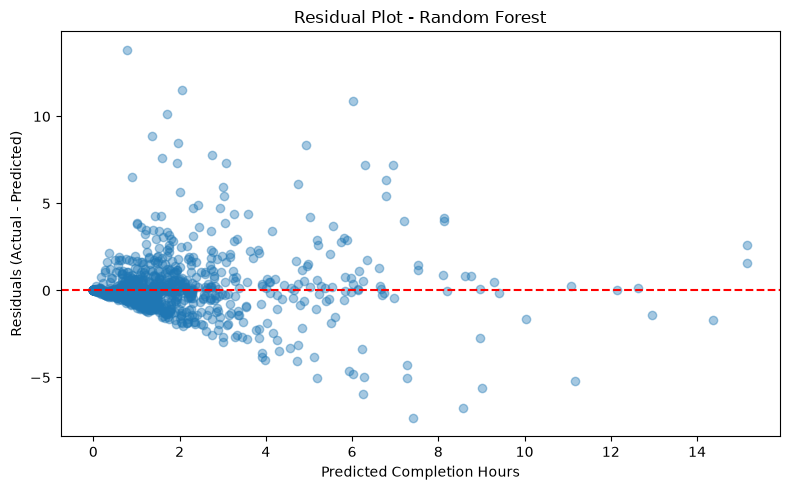

In [25]:
import matplotlib.pyplot as plt

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.4)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Completion Hours")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - Random Forest")

plt.tight_layout()
plt.show()

### 10 largest prediction errors

In [26]:
error_analysis = pd.DataFrame({
    "Actual Hours": y_test,
    "Predicted Hours": y_pred,
})

error_analysis["Residual"] = (
    error_analysis["Actual Hours"] -
    error_analysis["Predicted Hours"]
)

error_analysis["Absolute Error"] = (
    error_analysis["Residual"].abs()
)

error_analysis = error_analysis.sort_values(
    "Absolute Error",
    ascending=False
)

error_analysis.head(10)

,Actual Hours,Predicted Hours,Residual,Absolute Error
4564,14.619167,0.789392,13.829775,13.829775
3740,13.575000,2.056415,11.518585,11.518585
4524,16.938333,6.025058,10.913275,10.913275
4357,11.816667,1.704139,10.112528,10.112528
3001,10.220278,1.363839,8.856439,8.856439
3567,10.456111,1.956675,8.499436,8.499436
4574,13.259167,4.929239,8.329928,8.329928
3027,10.550278,2.757514,7.792764,7.792764
3560,9.183333,1.588011,7.595322,7.595322
4667,0.071389,7.405044,-7.333656,7.333656


### The difficult records

In [27]:
top_errors = error_analysis.head(10)

investigation = X_test.loc[top_errors.index].copy()

investigation["Actual Hours"] = top_errors["Actual Hours"]
investigation["Predicted Hours"] = top_errors["Predicted Hours"]
investigation["Absolute Error"] = top_errors["Absolute Error"]

investigation[
    [
        "agency",
        "complaint_type",
        "descriptor",
        "borough",
        "location_type",
        "created_hour",
        "Actual Hours",
        "Predicted Hours",
        "Absolute Error"
    ]
]

,agency,complaint_type,descriptor,borough,location_type,created_hour,Actual Hours,Predicted Hours,Absolute Error
4564,DEP,NOISE,JACKHAMMER,QUEENS,STREET/SIDEWALK,7,14.619167,0.789392,13.829775
3740,NYPD,NOISE - RESIDENTIAL,LOUD TALKING,MANHATTAN,RESIDENTIAL BUILDING/HOUSE,9,13.575000,2.056415,11.518585
4524,DHS,HOMELESS PERSON ASSISTANCE,NON-CHRONIC,QUEENS,SUBWAY,7,16.938333,6.025058,10.913275
4357,DOT,TRAFFIC SIGNAL CONDITION,WIRELESS,STATEN ISLAND,NaN,8,11.816667,1.704139,10.112528
3001,NYPD,ILLEGAL PARKING,DOUBLE PARKED BLOCKING VEHICLE,BROOKLYN,STREET/SIDEWALK,12,10.220278,1.363839,8.856439
3567,NYPD,NOISE - STREET/SIDEWALK,LOUD TALKING,QUEENS,STREET/SIDEWALK,10,10.456111,1.956675,8.499436
4574,HPD,HEAT/HOT WATER,ENTIRE BUILDING,BRONX,RESIDENTIAL BUILDING,7,13.259167,4.929239,8.329928
3027,DSNY,DEAD ANIMAL,OTHER,BROOKLYN,STREET,12,10.550278,2.757514,7.792764
3560,NYPD,ILLEGAL PARKING,POSTED PARKING SIGN VIOLATION,BROOKLYN,STREET/SIDEWALK,10,9.183333,1.588011,7.595322
4667,HPD,HEAT/HOT WATER,ENTIRE BUILDING,BRONX,RESIDENTIAL BUILDING,7,0.071389,7.405044,7.333656


### how performance changes with completion time

In [28]:
error_groups = pd.DataFrame({
    "Actual Hours": y_test,
    "Predicted Hours": y_pred
})

error_groups["Absolute Error"] = (
    error_groups["Actual Hours"] -
    error_groups["Predicted Hours"]
).abs()

error_groups["Duration Group"] = pd.cut(
    error_groups["Actual Hours"],
    bins=[0, 1, 3, 6, float("inf")],
    labels=["0–1 hour", "1–3 hours", "3–6 hours", "Above 6 hours"],
    include_lowest=True
)

group_analysis = error_groups.groupby(
    "Duration Group",
    observed=False
).agg(
    Request_Count=("Absolute Error", "count"),
    MAE=("Absolute Error", "mean"),
    Max_Error=("Absolute Error", "max")
)

group_analysis

,Request_Count,MAE,Max_Error
Duration Group,,,
0–1 hour,429,0.581322,7.333656
1–3 hours,309,0.722660,6.780472
3–6 hours,117,1.576968,5.603400
Above 6 hours,79,3.436279,13.829775


## Error Analysis and Model Limitations

### Error Analysis

The Random Forest model performs better on shorter service requests than on longer ones.

The subgroup analysis shows that MAE increases from 0.58 hours for requests completed within one hour to 3.44 hours for requests taking more than six hours.

The largest absolute prediction error is approximately 13.83 hours. Inspection of the largest errors also identified substantial underpredictions and some overpredictions.

### Limitations

1. The dataset covers only approximately 19 hours across two calendar dates, limiting temporal generalization.
2. The model has difficulty predicting unusually long completion times.
3. Some records have missing location information.
4. Completion time may depend on operational factors not included in the available features.
5. Predictions are estimates and should not be treated as guaranteed service completion times.

### create input samples 

In [29]:
sample_input = X_test.head(5).copy()

sample_input["created_date"] = pd.to_datetime(
    "2026-11-24 10:00:00"
)

sample_input = sample_input.drop(
    columns=[
        "created_hour",
        "created_dayofweek",
        "created_month"
    ]
)

sample_input.to_csv(
    PROJECT_ROOT / "outputs" / "sample_requests.csv",
    index=False
)

print("Sample input created.")
print(sample_input.head())

Sample input created.
     agency                 complaint_type  \
2776    DOB                   BUILDING/USE   
1634   NYPD                ILLEGAL PARKING   
1074    DOB  GENERAL CONSTRUCTION/PLUMBING   
2080   NYPD            NOISE - RESIDENTIAL   
4060    DOB  GENERAL CONSTRUCTION/PLUMBING   

                                             descriptor  \
2776   ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE   
1634                                    BLOCKED HYDRANT   
1074  SIDEWALK SHED/PIPE SCAFFORD - INADEQUATE DEFEC...   
2080                                   BANGING/POUNDING   
4060                    VENT/EXHAUST - ILLEGAL/IMPROPER   

                   location_type  incident_zip address_type  \
2776                         NaN       11419.0      ADDRESS   
1634             STREET/SIDEWALK       11201.0      ADDRESS   
1074                         NaN       11231.0      ADDRESS   
2080  RESIDENTIAL BUILDING/HOUSE       11432.0      ADDRESS   
4060                         Na